# Avaliação da recuperação semântica

Objetivo: medir relevância, polaridade, cobertura e redundância das avaliações recuperadas do Olist **antes da geração por LLM**. A avaliação distingue relevância estrita (tema e sentido) de relevância tolerante (apenas tema). Os resultados não representam frequência de reclamações no corpus completo.

**Protocolo:** executar uma busca por pergunta com `top_k=40`; comparar os prefixos de 10, 20 e 30 documentos; avaliar uma seleção alternativa com pelo menos 30 caracteres. Rótulos humanos são mantidos em arquivo separado e nunca sobrescritos pelo notebook.

In [1]:
"""Configure project paths and evaluation parameters."""

import sys
from pathlib import Path

import chromadb
import matplotlib.pyplot as plt
import pandas as pd
from sentence_transformers import SentenceTransformer

ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent
if not (ROOT_DIR / "src" / "retrieve.py").exists():
    raise FileNotFoundError("Open the notebook from the project root or notebooks/ directory.")
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.retrieve import CHROMA_PATH, COLLECTION_NAME, MODEL_NAME, retrieve_reviews

EVALUATION_DIR = ROOT_DIR / "evaluation"
CANDIDATES_PATH = EVALUATION_DIR / "retrieval_candidates.csv"
LABELS_PATH = EVALUATION_DIR / "retrieval_labels.csv"
TOP_K_VALUES = (10, 20, 30)
RETRIEVAL_K = 40
MIN_CHARS = 30
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
"""Load the existing Chroma collection and embedding model once."""

client = chromadb.PersistentClient(path=str(CHROMA_PATH))
collection = client.get_collection(COLLECTION_NAME)
model = SentenceTransformer(MODEL_NAME)

print(f"Model: {MODEL_NAME}")
print(f"Indexed reviews: {collection.count():,}")
print(f"Device: {model.device}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Indexed reviews: 42,138
Device: cpu


## Perguntas de avaliação

As nove perguntas originais cobrem temas do domínio. As novas perguntas incluem formulações livres, casos vagos e questões fora do escopo próximas ao comércio eletrônico. **Perguntas fora do escopo** serão examinadas quanto à presença de evidências, mas a taxa de recusa correta só poderá ser medida após implementar a política de suficiência e a geração.

In [3]:
"""Define in-domain, ambiguous and out-of-scope evaluation questions."""

questions = pd.DataFrame([
    ("Q01", "Entrega", "Quais avaliações relatam que o produto não foi entregue?", "domain"),
    ("Q02", "Entrega", "Quais clientes reclamam de atraso na entrega?", "domain"),
    ("Q03", "Entrega", "Existem relatos de produtos entregues antes do prazo?", "domain"),
    ("Q04", "Qualidade", "Quais avaliações mencionam produtos com defeito?", "domain"),
    ("Q05", "Qualidade", "Quais clientes relatam produtos diferentes do anunciado?", "domain"),
    ("Q06", "Atendimento", "Quais avaliações mencionam dificuldades com o atendimento?", "domain"),
    ("Q07", "Pós-venda", "Existem reclamações sobre devolução ou reembolso?", "domain"),
    ("Q08", "Satisfação", "Quais avaliações elogiam a qualidade dos produtos?", "domain"),
    ("Q09", "Satisfação", "Quais clientes recomendam a experiência de compra?", "domain"),
    ("Q10", "Fora do escopo", "Qual é o melhor smartphone de 2025?", "out_of_scope"),
    ("Q11", "Fora do escopo", "Qual será o faturamento da Olist em 2027?", "out_of_scope"),
    ("Q12", "Fora do escopo", "Qual é a cotação atual do dólar?", "out_of_scope"),
    ("Q13", "Fora do escopo", "Qual é a política de frete da Olist em 2025?", "out_of_scope"),
    ("Q14", "Fora do escopo", "A Olist oferece garantia estendida em 2026?", "out_of_scope"),
    ("Q15", "Fora do escopo", "Quanto custa anunciar na Olist hoje?", "out_of_scope"),
    ("Q16", "Fora do escopo", "Qual o prazo oficial de reembolso da Olist atualmente?", "out_of_scope"),
    ("Q17", "Vaga", "Entrega?", "ambiguous"),
    ("Q18", "Vaga", "Problemas com a compra", "ambiguous"),
    ("Q19", "Vaga", "Foi bom?", "ambiguous"),
], columns=["question_id", "category", "question", "scope"])

assert questions["question_id"].is_unique
display(questions)


,question_id,category,question,scope
0,Q01,Entrega,Quais avaliações relatam que o produto não foi...,domain
1,Q02,Entrega,Quais clientes reclamam de atraso na entrega?,domain
2,Q03,Entrega,Existem relatos de produtos entregues antes do...,domain
3,Q04,Qualidade,Quais avaliações mencionam produtos com defeito?,domain
4,Q05,Qualidade,Quais clientes relatam produtos diferentes do ...,domain
5,Q06,Atendimento,Quais avaliações mencionam dificuldades com o ...,domain
6,Q07,Pós-venda,Existem reclamações sobre devolução ou reembolso?,domain
7,Q08,Satisfação,Quais avaliações elogiam a qualidade dos produ...,domain
8,Q09,Satisfação,Quais clientes recomendam a experiência de com...,domain
9,Q10,Fora do escopo,Qual é o melhor smartphone de 2025?,out_of_scope


## Recuperação e candidatos

O recuperador realiza a deduplicação textual e a expansão adaptativa. `candidate_occurrences` conta ocorrências **somente entre os candidatos examinados**, não na base inteira. Aumentar `top_k` pode mudar a lista por efeito da busca aproximada; por isso os indicadores abaixo usam os prefixos de uma única execução com `top_k=40`.

In [4]:
"""Retrieve one ranked result list per question and retain diagnostics."""

def retrieve_question(question_id: str, question: str) -> list[dict]:
    """Retrieve reviews and attach question and retrieval diagnostics."""
    result = retrieve_reviews(question, collection, model, top_k=RETRIEVAL_K)
    return [
        {
            "question_id": question_id,
            "rank": rank,
            "review_id": review["review_id"],
            "document": review["document"],
            "similarity": review["similarity"],
            "review_score": review["review_score"],
            "n_chars": review["n_chars"],
            "candidate_occurrences": review["candidate_occurrences"],
            "candidates_examined": result["candidates_examined"],
            "candidate_limit_reached": result["candidate_limit_reached"],
            "retrieval_incomplete": result["retrieval_incomplete"],
        }
        for rank, review in enumerate(result["reviews"], start=1)
    ]

rows = [
    item
    for question in questions.itertuples(index=False)
    for item in retrieve_question(question.question_id, question.question)
]
candidates = pd.DataFrame(rows)
assert not candidates.duplicated(["question_id", "review_id"]).any()
assert (candidates["rank"] <= RETRIEVAL_K).all()
print(f"Retrieved rows: {len(candidates):,}")
display(candidates.head(10))


Retrieved rows: 686


,question_id,rank,review_id,document,similarity,review_score,n_chars,candidate_occurrences,candidates_examined,candidate_limit_reached,retrieval_incomplete
0,Q01,1,c84ca514000aa704df0258d693a07414,"Por favor, peço que chequem o porque do produt...",0.836153,1,70,1,200,True,False
1,Q01,2,09db4c326e7158211d66b9f994542274,PRODUTO NÃO ENTREGUE Gostaria de saber pq o pr...,0.799720,1,93,1,200,True,False
2,Q01,3,a151e6240e623d423a794e9d293cd9a9,O produto foi entregue no prazo Ainda não poss...,0.791842,3,97,1,200,True,False
3,Q01,4,4d05593294cb87f9412ec522d3c6333e,"ainda não recebi o produto, mas sem receber o ...",0.785985,2,81,1,200,True,False
4,Q01,5,2f59a88f994c5d6f802f0ddab0dd785b,Produto não entregue O produto ainda não foi e...,0.784567,1,108,1,200,True,False
5,Q01,6,2f0d288c4d136bc3db96726b533b70bb,O produto não foi entregue,0.781966,1,26,10,200,True,False
6,Q01,7,dd1deb7faf933a2bd44dd10cdfa9a953,nao satisfeito o produto ainda não foi entregue,0.781886,1,47,1,200,True,False
7,Q01,8,f9fe37d91c506b29a0b4d9107f667bde,"O produto foi comprado em 10/10/2016, não cheg...",0.780685,1,123,1,200,True,False
8,Q01,9,09b81fdc5bc3fdcebf3152e93428aac2,Produto não entregue O produto ainda não foi e...,0.779356,1,54,1,200,True,False
9,Q01,10,ad0bd5e96d27a747be07e136ab2d18c0,"Estou avaliando o fator entrega de mercadoria,...",0.779345,4,107,1,200,True,False


In [5]:
"""Export candidates without modifying the independent human labels."""

candidates.to_csv(CANDIDATES_PATH, index=False, encoding="utf-8-sig")
print(f"Candidates exported: {CANDIDATES_PATH.relative_to(ROOT_DIR)}")
print(f"Labels file exists: {LABELS_PATH.exists()}")


Candidates exported: evaluation/retrieval_candidates.csv
Labels file exists: True


## Rotulagem manual — protocolo pré-definido

Classifique **sem consultar a similaridade nem a posição original no ranking**, usando exclusivamente o texto e o sentido da pergunta:

- **2 — evidência direta:** confirma o fato solicitado, mesmo quando o sentimento geral é positivo. Em Q02, “Recomendo, mas houve atraso dos Correios” recebe 2.
- **1 — apenas tema:** aborda o assunto, mas apresenta sentido contrário ou neutro. Em Q03, “entregue no prazo” recebe 1 (não comprova entrega **antes** do prazo).
- **0 — irrelevante:** não informa sobre a questão, incluindo textos vazios de significado como “Avaliação.”.

Em Q01, “não recebi, por isso não posso avaliar” recebe 2. A nota da avaliação não determina o rótulo.

**Procedimento:** use a célula de inspeção sem similaridade; preencha e versione `evaluation/retrieval_labels.csv` com `question_id,review_id,relevance`. O notebook **nunca cria ou sobrescreve** esse arquivo. Os candidatos ficam em `evaluation/retrieval_candidates.csv`; os rótulos são vinculados por `(question_id, review_id)`, mesmo se o ranking mudar.

**Escopo inicial:** classificar as 9 perguntas `domain` até o rank 30 (**270 pares pergunta–avaliação**). Perguntas vagas e fora do escopo serão avaliadas separadamente quanto ao comportamento esperado, não por Precision@k.


In [6]:
"""Create the labeling template once; never overwrite existing labels."""
domain_ids = set(questions.loc[questions["scope"] == "domain", "question_id"])
LABELING_SEED = 42

if LABELS_PATH.exists():
    print("Labels file already exists; template not created.")
else:
    template = (
        candidates.loc[
            candidates["question_id"].isin(domain_ids) & (candidates["rank"] <= 30),
            ["question_id", "review_id", "document"],
        ]
        .merge(questions[["question_id", "question"]], on="question_id", how="left")
        .sample(frac=1, random_state=LABELING_SEED)          # embaralha todas as linhas
        .sort_values("question_id", kind="stable")           # reagrupa por pergunta, ordem interna embaralhada
        .reset_index(drop=True)
        .assign(relevance="")
        [["question_id", "review_id", "relevance", "question", "document"]]
    )
    template.to_csv(LABELS_PATH, index=False, encoding="utf-8-sig")
    print(f"Template created: {LABELS_PATH.relative_to(ROOT_DIR)} ({len(template)} rows)")

Labels file already exists; template not created.


In [7]:
"""Read and validate human labels; report labels missing from current candidates."""

def load_labels(path: Path) -> pd.DataFrame:
    """Load human labels without creating, rewriting or silently coercing errors."""
    columns = ["question_id", "review_id", "relevance"]
    if not path.exists():
        return pd.DataFrame(columns=columns)

    labels = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    if not set(columns).issubset(labels.columns):
        raise ValueError(f"Labels must contain: {columns}")
    labels = labels[columns].copy()
    if labels[["question_id", "review_id"]].eq("").any().any():
        raise ValueError("question_id and review_id cannot be empty.")
    if labels.duplicated(["question_id", "review_id"]).any():
        raise ValueError("Duplicate question_id/review_id labels found.")

    # Empty cells are permitted as pending labels; other values must be exactly 0, 1 or 2.
    raw = labels["relevance"]
    invalid = ~raw.isin(["", "0", "1", "2"])
    if invalid.any():
        bad = labels.loc[invalid, columns].head(5).to_dict("records")
        raise ValueError(f"Invalid relevance: expected blank, 0, 1 or 2. Examples: {bad}")
    labels["relevance"] = pd.to_numeric(raw.replace("", pd.NA), errors="raise")
    return labels

labels = load_labels(LABELS_PATH)
keys = ["question_id", "review_id"]
orphans = labels.merge(candidates[keys], on=keys, how="left", indicator=True)
orphans = orphans.loc[orphans["_merge"] == "left_only"]
judged = candidates.merge(labels, on=keys, how="left", validate="one_to_one")

print(f"Labeled retrieved rows: {judged['relevance'].notna().sum():,} / {len(judged):,}")
print(f"Orphan label rows (not in current candidates): {len(orphans):,}")
print(f"Labels file: {LABELS_PATH.relative_to(ROOT_DIR)}")
if not orphans.empty:
    display(orphans[keys].head(10))


Labeled retrieved rows: 270 / 686
Orphan label rows (not in current candidates): 0
Labels file: evaluation/retrieval_labels.csv


In [8]:
"""Inspect reviews in reproducibly shuffled order without similarity or rank."""

QUESTION_ID = "Q05"
DISPLAY_K = 30
selection = judged.loc[
    (judged["question_id"] == QUESTION_ID) & (judged["rank"] <= DISPLAY_K),
    ["review_id", "document", "relevance"],
].sample(frac=1, random_state=42)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(selection)


,review_id,document,relevance
187,b5bf33747d415ed07935e88b178c25d4,"super recomendo entregue na data,recomendo a venda de produtos",0.0
175,3639e59f95a0241360cc0c52933c5493,"otima loja que atende as necessidades do usuario,com entrega do produto antes do praso.",0.0
183,7cde8d21243a997106a2ae5149b39627,Produto recebido com conforme anunciado. Cliente satisfeito.,1.0
177,724728c35ef3cba0473f4bccf97fabba,Qualidade anunciada Produto entregue conforme o anunciado.,1.0
168,83d24d478d948b180721be139af82c2b,produto entregue conforme anunciado,1.0
169,fb71e4cb33cd34916b4755b686e03a08,Produto corresponde ao anunciado.,1.0
188,73ac4b31cf482438eb2cdf9f3d957029,"produto entregue no prazo,recomendo qualquer compra na loja",0.0
184,17102aaf6da7abbc1dd45cd8a6c7d3b8,Produto conforme descrito pelo vendedor,1.0
172,de4c6ffb7abeefe83b58365cc3b6674e,Produto entregue conforme anúncio,1.0
160,51a1578250f045f0a1044b653ee9b3be,produto diferente do anunciado,2.0


## Métricas de precisão

A Precision@k **estrita** conta apenas `relevance=2`; a **tolerante** conta `relevance≥1`. As métricas só serão publicadas para perguntas e valores de k **integralmente rotulados**. Perguntas vagas e fora do escopo são analisadas separadamente; não entram na média principal das perguntas de domínio.

In [9]:
"""Compute domain-only Precision@k and means from fully labeled prefixes."""

def precision_at_k(frame: pd.DataFrame, k: int) -> dict:
    """Calculate precision only when the entire top-k has human labels."""
    prefix = frame.loc[frame["rank"] <= k]
    complete = len(prefix) == k and prefix["relevance"].notna().all()
    return {
        "top_k": k,
        "labeled": int(prefix["relevance"].notna().sum()),
        "complete": bool(complete),
        "precision_strict": prefix["relevance"].eq(2).mean() if complete else float("nan"),
        "precision_tolerant": prefix["relevance"].ge(1).mean() if complete else float("nan"),
    }

domain_ids = set(questions.loc[questions["scope"] == "domain", "question_id"])
metrics = pd.DataFrame([
    {"question_id": question_id, **precision_at_k(frame, k)}
    for question_id, frame in judged.groupby("question_id")
    if question_id in domain_ids
    for k in TOP_K_VALUES
])
print("Precision@k by in-domain question (NaN = not fully labeled):")
display(metrics)

complete_metrics = metrics.loc[metrics["complete"]]
metric_means = (
    complete_metrics.groupby("top_k", as_index=False)
    .agg(
        questions_evaluated=("question_id", "nunique"),
        mean_precision_strict=("precision_strict", "mean"),
        mean_precision_tolerant=("precision_tolerant", "mean"),
    )
)
print("Means only over fully labeled in-domain questions:")
display(metric_means)


Precision@k by in-domain question (NaN = not fully labeled):


,question_id,top_k,labeled,complete,precision_strict,precision_tolerant
0,Q01,10,10,True,0.800000,0.800000
1,Q01,20,20,True,0.800000,0.850000
2,Q01,30,30,True,0.766667,0.866667
3,Q02,10,10,True,1.000000,1.000000
4,Q02,20,20,True,0.950000,1.000000
5,Q02,30,30,True,0.900000,0.966667
6,Q03,10,10,True,0.900000,1.000000
7,Q03,20,20,True,0.900000,1.000000
8,Q03,30,30,True,0.900000,1.000000
9,Q04,10,10,True,0.200000,1.000000


Means only over fully labeled in-domain questions:


,top_k,questions_evaluated,mean_precision_strict,mean_precision_tolerant
0,10,9,0.600000,0.933333
1,20,9,0.600000,0.916667
2,30,9,0.588889,0.900000


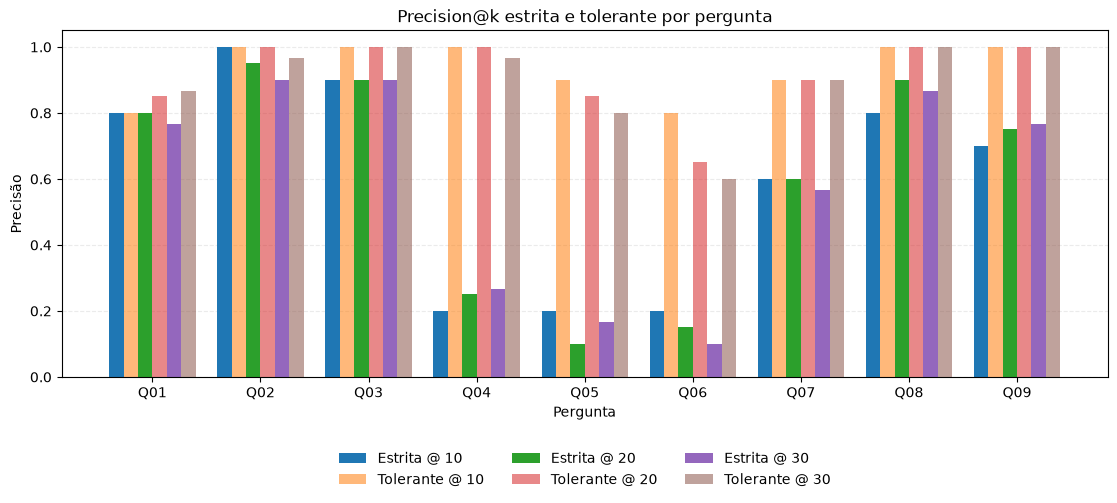

In [10]:

"""Plot Precision@k grouped by question, without legend overlap."""

import numpy as np

chart_data = metrics.loc[metrics["complete"]].copy()

if chart_data.empty:
    print("Nenhuma pergunta completamente rotulada.")
else:
    question_ids = sorted(chart_data["question_id"].unique())
    k_values = sorted(chart_data["top_k"].unique())

    fig, ax = plt.subplots(
        figsize=(max(12, len(question_ids) * 1.5), 5.5)
    )

    x = np.arange(len(question_ids))
    total_bars = len(k_values) * 2
    width = 0.8 / total_bars

    for i, k in enumerate(k_values):
        subset = (
            chart_data.loc[chart_data["top_k"] == k]
            .set_index("question_id")
            .reindex(question_ids)
        )

        strict = subset["precision_strict"].to_numpy(dtype=float)
        tolerant = subset["precision_tolerant"].to_numpy(dtype=float)

        strict_positions = x - 0.4 + (2 * i + 0.5) * width
        tolerant_positions = x - 0.4 + (2 * i + 1.5) * width

        ax.bar(
            strict_positions,
            strict,
            width=width,
            label=f"Estrita @ {k}",
        )

        ax.bar(
            tolerant_positions,
            tolerant,
            width=width,
            label=f"Tolerante @ {k}",
            alpha=0.55,
        )

    ax.set_title(
        "Precision@k estrita e tolerante por pergunta"
    )
    ax.set_xlabel("Pergunta")
    ax.set_ylabel("Precisão")
    ax.set_xticks(x)
    ax.set_xticklabels(question_ids)
    ax.set_ylim(0, 1.05)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25,
    )
    ax.set_axisbelow(True)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
    )

    plt.subplots_adjust(bottom=0.25)
    plt.show()


## Experimento com documentos curtos

Compare `n_chars≥30` com a linha de base, como **pós-filtro dos 40 resultados já recuperados**, apenas para k=10 e k=20. Um texto curto pode ser muito relevante (ex.: “Péssimo atendimento”); portanto, não excluímos esses textos do índice antecipadamente.

**Atenção à rotulagem:** para medir a variante em k=20, podem ser necessários rótulos além do rank 30. Resultados sem rótulos suficientes permanecerão `NaN`, sem estimativas artificiais. A comparação não equivale a uma busca filtrada diretamente no ChromaDB.


In [11]:

"""Compare baseline and minimum-length variants using paired questions."""

def select_variant(
    frame: pd.DataFrame,
    k: int,
    min_chars: int = 0
) -> pd.DataFrame:
    """Select the first k ranked reviews satisfying the length constraint."""
    eligible = frame.loc[frame["n_chars"] >= min_chars]
    return eligible.sort_values("rank").head(k)


variant_rows = []

for question_id, frame in judged.groupby("question_id"):
    if question_id not in domain_ids:
        continue

    for k in (10, 20):
        for variant, min_chars in (
            ("baseline", 0),
            ("min_30_chars", MIN_CHARS),
        ):
            selected = select_variant(frame, k, min_chars)

            complete = (
                len(selected) == k
                and selected["relevance"].notna().all()
            )

            variant_rows.append({
                "question_id": question_id,
                "top_k": k,
                "variant": variant,
                "selected": len(selected),
                "labeled": int(selected["relevance"].notna().sum()),
                "complete": bool(complete),
                "precision_strict": (
                    selected["relevance"].eq(2).mean()
                    if complete else float("nan")
                ),
                "precision_tolerant": (
                    selected["relevance"].ge(1).mean()
                    if complete else float("nan")
                ),
            })

variant_metrics = pd.DataFrame(variant_rows)

print("Resultados individuais das variantes:")
display(variant_metrics)

# Selecionar somente perguntas completas em AMBAS as variantes.
complete_pairs = (
    variant_metrics.loc[variant_metrics["complete"]]
    .groupby(["question_id", "top_k"])["variant"]
    .nunique()
)

common = (
    complete_pairs[complete_pairs == 2]
    .reset_index()[["question_id", "top_k"]]
)

paired = variant_metrics.merge(
    common,
    on=["question_id", "top_k"],
    how="inner",
    validate="many_to_one",
)

print("\nComparação pareada: mesmas perguntas nas duas variantes")

paired_means = (
    paired.groupby(["top_k", "variant"], as_index=False)
    .agg(
        questions_evaluated=("question_id", "nunique"),
        mean_precision_strict=("precision_strict", "mean"),
        mean_precision_tolerant=("precision_tolerant", "mean"),
    )
)

display(paired_means)

print("\nPerguntas completas em ambas as variantes:")
for k in (10, 20):
    ids = sorted(
        common.loc[
            common["top_k"] == k, "question_id"
        ].tolist()
    )
    print(f"k={k}: {len(ids)} perguntas — {', '.join(ids) or 'nenhuma'}")

# Identificar rótulos adicionais necessários para completar
# a comparação do filtro de 30 caracteres em k=20.
missing_labels = []

for question_id in sorted(domain_ids):
    frame = judged.loc[
        judged["question_id"] == question_id
    ].sort_values("rank")

    selected = select_variant(frame, 20, MIN_CHARS)

    for _, row in selected.loc[
        selected["relevance"].isna()
    ].iterrows():
        missing_labels.append({
            "question_id": question_id,
            "rank": int(row["rank"]),
            "review_id": row["review_id"],
            "document": row["document"],
        })

missing_df = pd.DataFrame(
    missing_labels,
    columns=["question_id", "rank", "review_id", "document"]
)

print(
    f"\nRótulos adicionais para completar "
    f"o filtro em k=20: {len(missing_df)}"
)
display(missing_df)


Resultados individuais das variantes:


,question_id,top_k,variant,selected,labeled,complete,precision_strict,precision_tolerant
0,Q01,10,baseline,10,10,True,0.80,0.80
1,Q01,10,min_30_chars,10,10,True,0.80,0.80
2,Q01,20,baseline,20,20,True,0.80,0.85
3,Q01,20,min_30_chars,20,20,True,0.75,0.85
4,Q02,10,baseline,10,10,True,1.00,1.00
5,Q02,10,min_30_chars,10,10,True,0.90,1.00
6,Q02,20,baseline,20,20,True,0.95,1.00
7,Q02,20,min_30_chars,20,19,False,NaN,NaN
8,Q03,10,baseline,10,10,True,0.90,1.00
9,Q03,10,min_30_chars,10,10,True,0.90,1.00



Comparação pareada: mesmas perguntas nas duas variantes


,top_k,variant,questions_evaluated,mean_precision_strict,mean_precision_tolerant
0,10,baseline,9,0.600000,0.933333
1,10,min_30_chars,9,0.588889,0.911111
2,20,baseline,7,0.614286,0.942857
3,20,min_30_chars,7,0.607143,0.935714



Perguntas completas em ambas as variantes:
k=10: 9 perguntas — Q01, Q02, Q03, Q04, Q05, Q06, Q07, Q08, Q09
k=20: 7 perguntas — Q01, Q03, Q04, Q05, Q07, Q08, Q09

Rótulos adicionais para completar o filtro em k=20: 3


,question_id,rank,review_id,document
0,Q02,31,16b23504ecebdbf6f75ce8addfd7e755,"Solicitei e efetuei o pag. dia 07/02, além do ..."
1,Q06,31,045d330f147f09c3bd2426266ec5d414,Nao tem boa avaliação por atraso na entrega
2,Q06,33,fc63cb40e62e6243efef9a40f4487978,"Problems existem, porem, necessario compreende..."


## Diagnóstico de suficiência e perguntas fora do escopo

A similaridade é apenas um sinal. Perguntas sobre políticas atuais, previsões ou fatos externos podem recuperar avaliações semanticamente próximas sem oferecer evidência válida. **Não fixar um limiar com base apenas nas perguntas atuais.** A recusa correta será medida na etapa da LLM e do controle de evidências.

In [12]:
"""Summarize maximum similarity and retrieval diagnostics by question."""

summary = (
    candidates.groupby("question_id", as_index=False)
    .agg(
        retrieved=("review_id", "count"),
        max_similarity=("similarity", "max"),
        min_similarity=("similarity", "min"),
        short_reviews=("n_chars", lambda values: int((values < MIN_CHARS).sum())),
        candidate_occurrences_sum=("candidate_occurrences", "sum"),
        candidates_examined=("candidates_examined", "max"),
        candidate_limit_reached=("candidate_limit_reached", "max"),
        retrieval_incomplete=("retrieval_incomplete", "max"),
    )
    .merge(questions, on="question_id", validate="one_to_one")
)
# Occurrences are counts within retrieved candidates, and sums over selected keys are not corpus frequencies.
display(summary[[
    "question_id", "scope", "retrieved", "max_similarity", "short_reviews",
    "candidate_occurrences_sum", "candidates_examined", "candidate_limit_reached", "retrieval_incomplete"
]])


,question_id,scope,retrieved,max_similarity,short_reviews,candidate_occurrences_sum,candidates_examined,candidate_limit_reached,retrieval_incomplete
0,Q01,domain,40,0.836153,7,76,200,True,False
1,Q02,domain,40,0.817220,13,53,200,True,False
2,Q03,domain,40,0.858691,1,103,200,True,False
3,Q04,domain,40,0.783426,13,54,200,True,False
4,Q05,domain,40,0.779277,3,46,200,True,False
5,Q06,domain,40,0.666060,15,47,200,True,False
6,Q07,domain,40,0.685304,1,41,200,True,False
7,Q08,domain,40,0.858308,9,84,200,True,False
8,Q09,domain,40,0.769773,5,41,200,True,False
9,Q10,out_of_scope,40,0.603243,0,40,200,True,False


In [13]:
"""Inspect the top five retrieved reviews for each out-of-scope question."""

out_of_scope_ids = questions.loc[questions["scope"] == "out_of_scope", "question_id"]
for question_id in out_of_scope_ids:
    question = questions.set_index("question_id").loc[question_id, "question"]
    print(f"\n{question_id}: {question}")
    subset = candidates.loc[
        (candidates["question_id"] == question_id) & (candidates["rank"] <= 5),
        ["rank", "document", "similarity"],
    ]
    with pd.option_context("display.max_colwidth", None):
        display(subset)



Q10: Qual é o melhor smartphone de 2025?


,rank,document,similarity
360,1,Capa de celular Super rápido a entrega recomendar muito,0.603243
361,2,ótimo celular muito bom gostei bem rápido e super leve eu recomendo.,0.581994
362,3,"Vale a pena O produto tem boa qualidade e tem tamanho suficiente para um celular 6"". Recomendo.",0.574648
363,4,"Entregaram antes do prazo recomendo pela agilidade, mas produto não, celular Samsung A5 2016 não aceitou o fone, voz abafada e baixa.",0.571831
364,5,Adorei o celular! Curtindo muito meu Samsung A 2016!,0.558048



Q11: Qual será o faturamento da Olist em 2027?


,rank,document,similarity
400,1,Produto dentro do esperado...no prazo,0.566030
401,2,Comprei o produto com a data de validade ate 2019 veio 2018,0.552711
402,3,"A previsão seria para o dia 5, mas temos que dar um desconto por causa dos correios.",0.544599
403,4,Dentro do prazo previsto.,0.539778
404,5,"Estou aguardando a entrega, que foi programada para dia 04/01/2018",0.536046



Q12: Qual é a cotação atual do dólar?


,rank,document,similarity
440,1,"Nota fiscal Então,o produto veio corretamente, mas a nota fiscal veio com um valor muito diferente do que foi pago . Paguei no total 95 reais a nota veio com valor de 8,00.",0.522216
441,2,vou receber ainda ? Como fica o pagamento ?,0.520311
442,3,"Excelente Só gostaria de saber porque foi cobrado um frete no valor de R$ 54,40?",0.493562
443,4,nota 1000,0.492117
444,5,EU RECOMENDO MUITO EXCELENTE PREÇO,0.483586


... (4 outputs left out)


Q15: Quanto custa anunciar na Olist hoje?


,rank,document,similarity
560,1,Produto Ok Produto entregue conforme anunciado. Bom custo beneficio!Recomendo!,0.642750
561,2,"Bom Achei diferente do anunciado,mas tá valendo pelo custo benefício!",0.621898
562,3,OtiMo preço,0.613855
563,4,Excelente preço. Atendimento no prazo.,0.613450
564,5,Produto igual ao anúncio.,0.599722



Q16: Qual o prazo oficial de reembolso da Olist atualmente?


,rank,document,similarity
600,1,"Já passou do prazo previsto e nada ainda, o relógio é para presente e a data até passou, se demorarem mais, quero reembolso",0.737968
601,2,Muito bom! Foi entregue entes do prazo.,0.719483
602,3,Foi entregue no prazo,0.709555
603,4,Foi entregue dentro do prazo,0.695366
604,5,Entregaram do prazo,0.693615


## Conclusões da avaliação

**Escopo.** Foram executadas 19 perguntas. A Precision@k foi medida apenas nas 9 perguntas de domínio (270 pares pergunta–avaliação, ranks 1–30). As 7 perguntas fora do escopo e as 3 vagas foram analisadas qualitativamente, sem Precision@k.

**Rótulos.** Escala 0/1/2 (2 = sustenta o sentido da pergunta; 1 = só o tema; 0 = irrelevante), atribuída por um anotador humano. Um pré-rótulo por LLM serviu de segundo anotador: concordância inicial de 80,4% (κ = 0,62; κ ponderado = 0,69), calculada antes da revisão de consistência. Das 53 divergências, 38 estavam na fronteira entre 1 e 2, principalmente em Q04 (defeito explícito × qualidade ruim) e Q07 (pedido × reclamação não atendida).

### Recuperação original (média de 9 perguntas)

| k | Precision estrita | Precision tolerante | Evidências diretas por pergunta |
|---|---|---|---|
| 10 | 60,0% | 93,3% | 6,0 |
| 20 | 60,0% | 91,7% | 12,0 |
| 30 | 58,9% | 90,0% | 17,7 |

- A precisão estrita permanece estável de k=10 a k=30, e a tolerante cai 3 pontos. Aumentar k de 10 para 30 eleva a média de evidências diretas de 6,0 para 17,7 por pergunta, mantendo precisão estrita semelhante. Entretanto, também aumenta a quantidade absoluta de avaliações relacionadas apenas ao tema ou irrelevantes, exigindo maior capacidade de seleção de evidências na etapa de geração.
- O recuperador acerta o **tema**, mas não o **sentido**. Em k=30, Q04 (defeito) tem precisão estrita de 26,7% contra 96,7% tolerante; Q05 (diferente do anunciado), 16,7% contra 80,0%; Q06 (dificuldades no atendimento), 10,0% contra 60,0%.
- Q06 é o caso mais fraco: até a precisão tolerante cai de 80% para 60% com k, porque o ranking se enche de textos curtos e genéricos.

### Experimento: filtro de 30 caracteres (pós-filtro dos 40 resultados)

| k | Perguntas | Estrita (base → filtro) | Tolerante (base → filtro) |
|---|---|---|---|
| 10 | 9 | 60,0% → 58,9% | 93,3% → 91,1% |
| 20 | 7 | 61,4% → 60,7% | 94,3% → 93,6% |

Em k=20, Q02 e Q06 foram excluídas por faltarem 3 rótulos além do rank 30, que não foram atribuídos por decisão. Essas duas perguntas estão entre as com mais textos curtos entre os candidatos (13 e 15 de 40), mas a comparação em k=10 as inclui. O filtro não trouxe ganho em nenhuma configuração e pode excluir textos curtos relevantes. **Decisão: manter a recuperação original.**

### Perguntas fora do escopo e vagas
- A similaridade máxima das perguntas fora do escopo (0,52–0,74) se sobrepõe à das de domínio (0,67–0,86). Q16 (0,738) supera Q06 (0,666) e Q07 (0,685). **Um limiar de similaridade isolado não separa evidência suficiente de insuficiente.**
- As avaliações recuperadas para essas perguntas são lexicalmente próximas ("prazo", "garantia", "anunciado"), mas não respondem à pergunta.
- Q17 e Q19 retornaram apenas 4 e 2 avaliações distintas após a deduplicação, mesmo com o exame de 200 candidatos. O resultado evidencia uma limitação da recuperação para consultas vagas e altamente redundantes.

### Limitações
- Mede-se precisão, não recall: não se sabe quantas evidências relevantes existem fora do top-k.
- São 9 perguntas, um anotador humano e um segundo anotador LLM; as médias são descritivas, sem teste de significância.
- Q04 e Q07 dependem do critério adotado (defeito explícito; reclamação não atendida).
- `candidate_occurrences` conta ocorrências entre os candidatos examinados, não a frequência na base.

### Decisões para a etapa de geração
- Recuperar 20 a 30 avaliações e instruir o LLM a filtrar por sentido e citar apenas as que sustentam a afirmação.
- A suficiência de evidência será avaliada por regras explícitas e pela análise contextual do LLM, sem depender exclusivamente de limiares de similaridade. A capacidade do modelo de identificar evidências suficientes e recusar respostas sem suporte será avaliada empiricamente.
- Pendentes: testar reescrita da pergunta ou reranker em Q04–Q06 e definir o LLM.